# Modelado con los héroes nuevos: ¿se sostiene la composición?

Ciencia de Datos · UTN FRM · 2026 · Continuación de la Entrega 3

El notebook v3 eligió una regresión logística sobre la **composición** de los equipos, entrenada con partidas de agosto y septiembre, cuando el juego tenía 38 héroes. Entre el 21/09 y fines de octubre Valve agregó seis más, y el DAG ahora arma un catálogo por corte (rama `feat/catalogo-dinamico-heroes`). Este notebook repite la misma comparación sobre cinco cortes de noviembre, con 44 héroes, y responde tres preguntas:

1. **¿Se sostiene la elección?** Con las mismas reglas de la Entrega 3, ¿la composición sigue empatando con la mejor combinación, gana o pierde?
2. **¿Cuánto pierde el modelo de la Entrega 3 si no se reentrena?** Es el modelo que hoy usa la aplicación.
3. **¿Qué aprende de los héroes nuevos?**

Se corre de arriba hacia abajo, con la semilla definida al principio y todo lo que se le hace a los datos adentro de un `Pipeline`. Los números de la prosa salen de celdas ejecutadas.

## 0. Qué cambió respecto del notebook v3

- **Los datos.** Cinco cortes nuevos (01/11, 03/11, 05/11, 07/11 y 09/11), de 10.000 partidas cada uno, generados con el DAG de catálogo por corte. Están en `silver/catalogo_dinamico/`; los cortes de la Entrega 3 no se tocan.
- **Por qué esas fechas.** Hasta el 30/10 el 99 % de las partidas tenía algún héroe nuevo, como en una semana de lanzamiento; desde el 31/10 baja a entre 60 % y 64 % y se mantiene. Los cinco cortes caen en el período estable y van cada dos días, para tener los mismos tres pasos de validación que en septiembre.
- **Las columnas.** 44 de composición (los 38 de siempre más Deadman Danny, Rat King, Solomon, Violet, Nurse Harrow y Baba) y las mismas 28 ventajas: 72 en total.
- **El diseño, igual.** La misma métrica, el mismo walk-forward con `m = 1`, las mismas grillas y el mismo criterio de elección, escrito antes de mirar los resultados.

In [1]:
# Las herramientas de todo el notebook
import json, pickle, re, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

SEMILLA = 42
np.random.seed(SEMILLA)

VERDE_AZUL, TERRACOTA, GRIS, NARANJA = "#009086", "#B5402C", "#7a7974", "#d4860b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 80)


def c(x, d=3):
    '''Número con coma decimal, para la prosa en castellano.'''
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    '''Entero con separador de miles (el § se vuelve punto recién en leer).'''
    return f"{x:,}".replace(",", "§")


def leer(texto):
    '''Muestra prosa en castellano: coma decimal fuera de los `códigos`, punto de miles donde hay §.'''
    partes = texto.split("`")
    for i in range(0, len(partes), 2):
        partes[i] = re.sub(r"(?<=\d)\.(?=\d)", ",", partes[i])
    display(Markdown("`".join(partes).replace("§", ".")))

## 1. Los datos: cinco cortes de noviembre con su catálogo

Cada corte trae su `catalogo.json`: los héroes que tenía el juego en ese momento, con el nombre de columna que les fijó el registro. Se juntan los catálogos de los cinco cortes; un héroe que faltara en alguno tendría su columna en cero ahí, que es lo que significa la codificación +1/−1/0.

In [2]:
RAIZ = Path.cwd() if (Path.cwd() / "include").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "include"))
from deadlock import catalogo as cat
from deadlock import schema

PLATA = RAIZ / "include" / "output" / "silver" / "catalogo_dinamico"
partes, catalogos, NOMBRE = [], {}, {}
for carpeta in sorted(PLATA.glob("corte=*/dias=14/k=100")):
    corte = carpeta.parts[-3].split("=")[1]
    t = pd.read_parquet(carpeta / "features.parquet")
    t["corte"] = corte
    partes.append(t)
    catalogo = json.loads((carpeta / "catalogo.json").read_text(encoding="utf-8"))
    catalogos[corte] = cat.heroes_de(catalogo)
    NOMBRE.update({f"hero_{d['slug']}": d["nombre"] for d in catalogo["detalle"]})   # el nombre oficial, de la API

HEROES = sorted({h for lista in catalogos.values() for h in lista})
COMPOSICION = schema.composicion(HEROES)
FEATURES = schema.feature_columns(HEROES)
NUEVOS = [f"hero_{s}" for i, s in HEROES if i not in schema.HERO_IDS]

df = pd.concat(partes, ignore_index=True)
df[COMPOSICION] = df[COMPOSICION].fillna(0).astype(int)
assert df["match_id"].is_unique, "una partida aparece en dos cortes"
anteriores = int(sum((pd.to_datetime(t["match_date"]) < pd.Timestamp(c_)).sum() for c_, t in df.groupby("corte")))
assert anteriores == 0, "hay partidas anteriores a su corte"

cortes = df.groupby("corte").agg(partidas=("match_id", "size"), gana_A=("winner", lambda s: s.eq("A").mean()))
cortes["héroes en el catálogo"] = pd.Series({k: len(v) for k, v in catalogos.items()})
cortes["con algún héroe nuevo"] = df.groupby("corte")[NUEVOS].apply(lambda t: t.ne(0).any(axis=1).mean())
cortes.round(3)

,partidas,gana_A,héroes en el catálogo,con algún héroe nuevo
corte,,,,
2026-11-01,10000,0.490,44,0.632
2026-11-03,9995,0.502,44,0.640
2026-11-05,10000,0.500,44,0.637
2026-11-07,10000,0.498,44,0.641
2026-11-09,9998,0.500,44,0.638


In [3]:
por_heroe = df[NUEVOS].ne(0).groupby(df["corte"]).sum().T
por_heroe.index = [NOMBRE[k] for k in por_heroe.index]
leer(f'''Hay **{len(cortes)} cortes** y **{miles(len(df))} partidas**, con un catálogo de **{len(HEROES)} héroes** ({len(NUEVOS)} nuevos respecto de la Entrega 3) y **{len(FEATURES)} columnas** para el modelo. Ninguna partida es anterior a su corte. El equipo A gana entre el {cortes['gana_A'].min():.1%} y el {cortes['gana_A'].max():.1%} de las veces, como en septiembre, y entre el {cortes['con algún héroe nuevo'].min():.0%} y el {cortes['con algún héroe nuevo'].max():.0%} de las partidas tiene algún héroe nuevo. El menos jugado de los nuevos aparece en {miles(int(por_heroe.min().min()))} partidas de un corte: alcanza para estimarle un peso.''')
por_heroe

Hay **5 cortes** y **49.993 partidas**, con un catálogo de **44 héroes** (6 nuevos respecto de la Entrega 3) y **72 columnas** para el modelo. Ninguna partida es anterior a su corte. El equipo A gana entre el 49,0% y el 50,2% de las veces, como en septiembre, y entre el 63% y el 64% de las partidas tiene algún héroe nuevo. El menos jugado de los nuevos aparece en 769 partidas de un corte: alcanza para estimarle un peso.

corte,2026-11-01,2026-11-03,2026-11-05,2026-11-07,2026-11-09
Deadman Danny,1809,1869,1842,1709,1744
Rat King,2600,2484,2435,2713,2471
Solomon,769,843,822,846,919
Violet,1444,1357,1317,1300,1230
Nurse Harrow,1329,1450,1574,1675,1751
Baba,878,1016,966,803,893


## 2. El planteo, igual que en la Entrega 3

- **Objetivo:** `winner`, 1 si gana el equipo A.
- **Métrica:** ROC AUC, con la accuracy al lado. Los motivos son los de la sección 2.2 del v3: la aplicación muestra una probabilidad, y A y B son etiquetas simétricas.
- **Partición:** el test es el corte más reciente, el 09/11, entero. La validación es walk-forward con ventana `m = 1`: se entrena con un corte y se valida con el siguiente.

In [4]:
y = df["winner"].eq("A").astype(int)
X = df[FEATURES + ["average_badge_diff"]]
CORTE_TEST = df["corte"].max()
es_test = df["corte"].eq(CORTE_TEST)
VENTANA = 1
X_train, y_train, g_train = X[~es_test], y[~es_test], df.loc[~es_test, "corte"]
X_test, y_test = X[es_test], y[es_test]
ESCALA = {"auc": "roc_auc", "acc": "accuracy"}


class VentanaDeslizante:
    '''Walk-forward con ventana deslizante: entrena con los m cortes anteriores y valida con el siguiente.'''

    def __init__(self, m=1):
        self.m = m

    def split(self, X, y=None, groups=None):
        g = np.asarray(groups)
        orden = np.sort(np.unique(g))
        for i in range(self.m, len(orden)):
            yield np.flatnonzero(np.isin(g, orden[i - self.m:i])), np.flatnonzero(g == orden[i])

    def get_n_splits(self, X=None, y=None, groups=None):
        return len(np.unique(groups)) - self.m


cv = VentanaDeslizante(VENTANA)
pd.DataFrame([{"paso": i + 1, "entrena con": ", ".join(sorted(g_train.iloc[e].unique())),
               "valida con": ", ".join(sorted(g_train.iloc[v].unique())), "filas que entrena": len(e), "filas que valida": len(v)}
              for i, (e, v) in enumerate(cv.split(X_train, y_train, g_train))]).set_index("paso")

,entrena con,valida con,filas que entrena,filas que valida
paso,,,,
1,2026-11-01,2026-11-03,10000,9995
2,2026-11-03,2026-11-05,9995,10000
3,2026-11-05,2026-11-07,10000,10000


## 3. El pipeline y los bloques de columnas

Los mismos bloques que el v3; cambia el tamaño de la composición.

| Bloque | Qué tiene |
|---|---|
| `una_columna` | `hero_winrate_adv_mean`: la regla |
| `winrates` | las tres medias de winrate de la API |
| `counter_synergy` | el resto de cruces y parejas (22) |
| `fuerza` | la fuerza individual entera (4) |
| `composicion` | un héroe por columna, ±1 (**44**) |
| `todas` | composición y ventajas (**72**) |

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

MEDIAS_WINRATE = ["hero_winrate_adv_mean", "counter_winrate_adv_mean", "synergy_winrate_adv_mean"]
BLOQUES = {
    "una_columna":     ["hero_winrate_adv_mean"],
    "winrates":        MEDIAS_WINRATE,
    "counter_synergy": [k for k in schema.COUNTER + schema.SYNERGY if k not in MEDIAS_WINRATE],
    "fuerza":          schema.HERO_WINRATE,
    "composicion":     COMPOSICION,
    "todas":           FEATURES,
}
UNA, TODAS, COMP = ("una_columna",), ("todas",), ("composicion",)
ORDEN = ("una_columna", "winrates", "counter_synergy", "fuerza", "composicion", "todas")
NOMBRE_BLOQUES = {(b,): f"{b.replace('una_columna', 'una columna').replace('composicion', 'composición')} ({len(BLOQUES[b])})" for b in ORDEN}


def columnas_de(bloques):
    return list(dict.fromkeys(col for b in bloques for col in BLOQUES[b]))


def legible(v):
    return NOMBRE_BLOQUES.get(v, v) if isinstance(v, tuple) else v


class ElegirColumnas(BaseEstimator, TransformerMixin):
    '''Se queda con las columnas de los bloques pedidos: los bloques son un hiperparámetro más.'''

    def __init__(self, bloques=TODAS):
        self.bloques = bloques

    def fit(self, X, y=None):
        self.columnas_ = columnas_de(self.bloques)
        return self

    def transform(self, X):
        return X[self.columnas_]


def armar(modelo, bloques=TODAS):
    return Pipeline([("elegir", ElegirColumnas(bloques)), ("escalar", StandardScaler()), ("modelo", modelo)])


def medir(pipe, cv=cv, Xt=None, yt=None, gt=None):
    '''AUC y accuracy en los pasos del walk-forward: media, desvío y AUC en train.'''
    Xt, yt, gt = (X_train, y_train, g_train) if Xt is None else (Xt, yt, gt)
    r = cross_validate(pipe, Xt, yt, groups=gt, cv=cv, scoring=ESCALA, return_train_score=True, n_jobs=-1)
    return {"AUC": r["test_auc"].mean(), "desvío AUC": r["test_auc"].std(), "accuracy": r["test_acc"].mean(),
            "AUC en train": r["train_auc"].mean()}


pd.Series({legible((b,)): len(BLOQUES[b]) for b in ORDEN}, name="columnas")

una columna (1)          1
winrates (3)             3
counter_synergy (22)    22
fuerza (4)               4
composición (44)        44
todas (72)              72
Name: columnas, dtype: int64

## 4. La comparación: el piso, la regla y las cuatro familias

Las mismas referencias y familias de la sección 4 del v3, con sus valores por defecto, sobre las 72 columnas.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modelos = {
    "piso (dummy)":        armar(DummyClassifier(strategy="most_frequent"), UNA),
    "regla: una columna":  armar(LogisticRegression(), UNA),
    "regresión logística": armar(LogisticRegression(max_iter=5000)),
    "árbol de decisión":   armar(DecisionTreeClassifier(random_state=SEMILLA)),
    "random forest":       armar(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA)),
    "gradient boosting":   armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
}
comparacion = pd.DataFrame({n: medir(p) for n, p in modelos.items()}).T
comparacion.round(4)

,AUC,desvío AUC,accuracy,AUC en train
piso (dummy),0.5000,0.0000,0.4999,0.5000
regla: una columna,0.6130,0.0052,0.5835,0.6104
regresión logística,0.6196,0.0056,0.5852,0.6433
árbol de decisión,0.5191,0.0064,0.5191,1.0000
random forest,0.6033,0.0037,0.5748,1.0000
gradient boosting,0.5948,0.0034,0.5708,0.9382


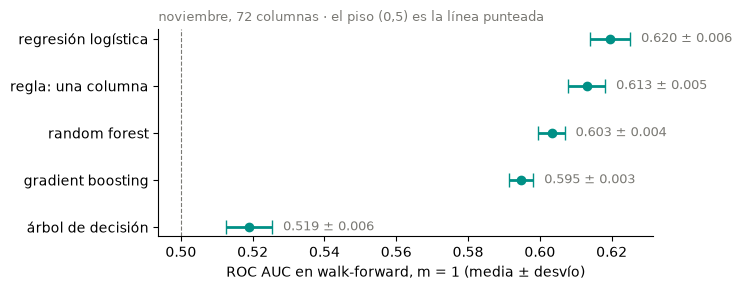

In [7]:
tabla = comparacion.drop(index="piso (dummy)").sort_values("AUC")
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.errorbar(tabla["AUC"], tabla.index, xerr=tabla["desvío AUC"], fmt="o", color=VERDE_AZUL, ecolor=VERDE_AZUL, elinewidth=2, capsize=5)
for nombre, fila in tabla.iterrows():
    ax.text(fila["AUC"] + fila["desvío AUC"] + 0.003, nombre, f"{fila['AUC']:.3f} ± {fila['desvío AUC']:.3f}", va="center", fontsize=9, color=GRIS)
ax.axvline(0.5, color=GRIS, lw=0.8, ls="--")
ax.set_xlabel("ROC AUC en walk-forward, m = 1 (media ± desvío)")
ax.set_title("noviembre, 72 columnas · el piso (0,5) es la línea punteada", fontsize=9, color=GRIS, loc="left")
plt.tight_layout()
plt.show()

In [8]:
regla = comparacion.loc["regla: una columna"]
mejor_comp = comparacion.drop(index=["piso (dummy)", "regla: una columna"])["AUC"].idxmax()
leer(f'''La regla de una columna llega a AUC **{c(regla['AUC'], 4)}** (± {c(regla['desvío AUC'], 4)}). La mejor de las cuatro familias con valores por defecto es `{mejor_comp}`, con {c(comparacion.loc[mejor_comp, 'AUC'], 4)}. El árbol sin límite vuelve a memorizar (AUC {c(comparacion.loc['árbol de decisión', 'AUC en train'])} en train y {c(comparacion.loc['árbol de decisión', 'AUC'])} en validación), igual que en septiembre.''')

La regla de una columna llega a AUC **0,6130** (± 0,0052). La mejor de las cuatro familias con valores por defecto es `regresión logística`, con 0,6196. El árbol sin límite vuelve a memorizar (AUC 1,000 en train y 0,519 en validación), igual que en septiembre.

### 4.1 Qué le pasaría al número si los pedazos se armaran al azar

In [9]:
from sklearn.model_selection import StratifiedKFold

al_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
validaciones = pd.DataFrame({n: {"walk-forward (m = 1)": comparacion.loc[n, "AUC"], "al azar (StratifiedKFold)": medir(modelos[n], cv=al_azar)["AUC"]}
                             for n in ["regla: una columna", "regresión logística", "gradient boosting"]}).T
validaciones["diferencia"] = validaciones["al azar (StratifiedKFold)"] - validaciones["walk-forward (m = 1)"]
validaciones.round(3)

,walk-forward (m = 1),al azar (StratifiedKFold),diferencia
regla: una columna,0.613,0.610,-0.003
regresión logística,0.620,0.630,0.010
gradient boosting,0.595,0.614,0.019


## 5. El ajuste

Las mismas grillas que la sección 5 del v3: la logística mueve el bloque de columnas y `C`; las otras tres familias, los hiperparámetros que controlan su complejidad.

In [10]:
from sklearn.model_selection import GridSearchCV

grillas = {
    "regresión logística": (armar(LogisticRegression(max_iter=5000)),
                            {"elegir__bloques": [(b,) for b in ORDEN], "modelo__C": [0.001, 0.01, 0.1, 1, 10]}),
    "árbol de decisión":   (armar(DecisionTreeClassifier(random_state=SEMILLA)),
                            {"modelo__max_depth": [3, 6, 10], "modelo__min_samples_leaf": [20, 100, 500]}),
    "random forest":       (armar(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA)),
                            {"modelo__max_depth": [6, 12, None], "modelo__min_samples_leaf": [20, 100]}),
    "gradient boosting":   (armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
                            {"modelo__learning_rate": [0.03, 0.1], "modelo__max_leaf_nodes": [7, 31], "modelo__max_iter": [100, 300]}),
}
busquedas = {n: GridSearchCV(p, g, cv=cv, scoring=ESCALA, refit="auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)
             for n, (p, g) in grillas.items()}
pd.DataFrame({n: {"AUC por defecto": comparacion.loc[n, "AUC"], "AUC mejor de la grilla": b.best_score_,
                  "desvío": b.cv_results_["std_test_auc"][b.best_index_], "mejores hiperparámetros": {k.split('__')[-1]: legible(v) for k, v in b.best_params_.items()}}
              for n, b in busquedas.items()}).T

,AUC por defecto,AUC mejor de la grilla,desvío,mejores hiperparámetros
regresión logística,0.619616,0.62312,0.007689,"{'bloques': 'todas (72)', 'C': 0.001}"
árbol de decisión,0.519075,0.606327,0.006833,"{'max_depth': 3, 'min_samples_leaf': 100}"
random forest,0.603278,0.614742,0.006134,"{'max_depth': 12, 'min_samples_leaf': 100}"
gradient boosting,0.594806,0.614301,0.005598,"{'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 7}"


### 5.1 La tabla entera de la logística

In [11]:
lr = busquedas["regresión logística"]
r = pd.DataFrame(lr.cv_results_)
r["bloques"] = r["param_elegir__bloques"].map(legible)
r["n_columnas"] = r["param_elegir__bloques"].map(lambda b: len(columnas_de(b)))
tabla_lr = r[["bloques", "param_modelo__C", "mean_test_auc", "std_test_auc", "mean_test_acc", "mean_train_auc"]].rename(
    columns={"param_modelo__C": "C", "mean_test_auc": "AUC", "std_test_auc": "desvío AUC", "mean_test_acc": "accuracy", "mean_train_auc": "AUC en train"})
tabla_lr.sort_values("AUC", ascending=False).round(4)

,bloques,C,AUC,desvío AUC,accuracy,AUC en train
25,todas (72),0.001,0.6231,0.0077,0.5904,0.6364
24,composición (44),10.000,0.6226,0.0072,0.5906,0.6362
23,composición (44),1.000,0.6226,0.0072,0.5907,0.6362
22,composición (44),0.100,0.6226,0.0072,0.5907,0.6362
21,composición (44),0.010,0.6225,0.0072,0.5915,0.6361
26,todas (72),0.010,0.6222,0.0071,0.5878,0.6393
27,todas (72),0.100,0.6215,0.0061,0.5876,0.6417
20,composición (44),0.001,0.6212,0.0075,0.5906,0.6351
29,todas (72),10.000,0.6202,0.0063,0.5860,0.6439
8,winrates (3),1.000,0.6201,0.0040,0.5862,0.6198


### 5.2 La elección, con el criterio de la Entrega 3

El mismo criterio de la sección 5.2 del v3, escrito antes de correr la grilla:

1. **El empate:** entran las combinaciones a menos de un desvío de la mejor.
2. **Dentro del empate, la que no depende de una tabla externa:** la composición se arma con los 12 héroes elegidos; todos los demás bloques necesitan las estadísticas de la API.

In [12]:
mejor_lr = r.loc[lr.best_index_]
umbral = mejor_lr["mean_test_auc"] - mejor_lr["std_test_auc"]
r["en el empate"] = r["mean_test_auc"] >= umbral
por_bloque = (r.sort_values("mean_test_auc", ascending=False).groupby("bloques", sort=False).first()
              [["n_columnas", "param_modelo__C", "mean_test_auc", "std_test_auc", "mean_test_acc", "mean_train_auc", "en el empate"]])
por_bloque.columns = ["columnas", "mejor C", "AUC", "desvío AUC", "accuracy", "AUC en train", "¿en el empate?"]
por_bloque["¿necesita estadísticas de héroes?"] = np.where(por_bloque.index == legible(COMP), "no", "sí")
por_bloque.round(4)

,columnas,mejor C,AUC,desvío AUC,accuracy,AUC en train,¿en el empate?,¿necesita estadísticas de héroes?
bloques,,,,,,,,
todas (72),72,0.001,0.6231,0.0077,0.5904,0.6364,True,sí
composición (44),44,10.000,0.6226,0.0072,0.5906,0.6362,True,no
winrates (3),3,1.000,0.6201,0.0040,0.5862,0.6198,True,sí
una columna (1),1,0.001,0.6130,0.0052,0.5832,0.6104,False,sí
fuerza (4),4,0.010,0.6119,0.0071,0.5801,0.6115,False,sí
counter_synergy (22),22,0.001,0.6111,0.0064,0.5787,0.6130,False,sí


In [13]:
comp_fila, mejor_fila = por_bloque.loc[legible(COMP)], por_bloque.iloc[0]
en_empate = por_bloque.index[por_bloque["¿en el empate?"]].tolist()
comp_es_mejor = mejor_fila.name == legible(COMP)
leer(f'''La mejor combinación de la grilla es `{mejor_fila.name}`, con AUC **{c(mejor_fila['AUC'], 4)}** ± {c(mejor_fila['desvío AUC'], 4)}; el empate llega hasta {c(umbral, 4)} y en él quedan {', '.join(f'`{b}`' for b in en_empate)}. {'**La composición ya no empata desde atrás: es la mejor de la grilla.** ' if comp_es_mejor else ('La composición está en el empate, con ' + c(comp_fila['AUC'], 4) + '. ' if comp_fila['¿en el empate?'] else 'La composición queda fuera del empate, con ' + c(comp_fila['AUC'], 4) + '. ')}En septiembre era al revés: la mejor era `winrates (3)` y la composición empataba desde atrás (la sección 8 pone los dos meses lado a lado). {'Con el criterio de la Entrega 3 se elige otra vez la composición.' if comp_fila['¿en el empate?'] else 'Con el criterio de la Entrega 3, la composición ya no se elegiría.'}''')

La mejor combinación de la grilla es `todas (72)`, con AUC **0,6231** ± 0,0077; el empate llega hasta 0,6154 y en él quedan `todas (72)`, `composición (44)`, `winrates (3)`. La composición está en el empate, con 0,6226. En septiembre era al revés: la mejor era `winrates (3)` y la composición empataba desde atrás (la sección 8 pone los dos meses lado a lado). Con el criterio de la Entrega 3 se elige otra vez la composición.

### 5.3 Las otras familias, sobre las mismas 44 columnas

In [14]:
busquedas_comp = {}
for nombre, (pipe, grilla) in grillas.items():
    if nombre == "regresión logística":
        grilla = {"modelo__C": grilla["modelo__C"]}
    busquedas_comp[nombre] = GridSearchCV(clone(pipe).set_params(elegir__bloques=COMP), grilla, cv=cv, scoring=ESCALA,
                                          refit="auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)
familias_comp = pd.DataFrame({n: {"AUC": b.best_score_, "desvío AUC": b.cv_results_["std_test_auc"][b.best_index_],
                                  "AUC en train": b.cv_results_["mean_train_auc"][b.best_index_],
                                  "mejores hiperparámetros": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in b.best_params_.items())}
                              for n, b in busquedas_comp.items()}).T
familias_comp

,AUC,desvío AUC,AUC en train,mejores hiperparámetros
regresión logística,0.622561,0.007172,0.636166,C=10
árbol de decisión,0.552244,0.008151,0.572681,"max_depth=10, min_samples_leaf=500"
random forest,0.603954,0.006278,0.789029,"max_depth=None, min_samples_leaf=20"
gradient boosting,0.602738,0.007439,0.698678,"learning_rate=0.1, max_iter=100, max_leaf_nodes=7"


In [15]:
lr_comp = busquedas_comp["regresión logística"]
sd_lr_comp = lr_comp.cv_results_["std_test_auc"][lr_comp.best_index_]
otra_comp = max((n for n in busquedas_comp if n != "regresión logística"), key=lambda n: busquedas_comp[n].best_score_)
ventaja_otra = busquedas_comp[otra_comp].best_score_ - lr_comp.best_score_
leer(f'''Sobre la composición, la logística llega a **{c(lr_comp.best_score_, 4)}** y la mejor de las otras familias, `{otra_comp}`, a {c(busquedas_comp[otra_comp].best_score_, 4)}: {'le gana por más que el desvío.' if ventaja_otra > sd_lr_comp else f"queda {c(-ventaja_otra, 4)} por debajo, así que se queda la logística, igual que en septiembre."}''')

Sobre la composición, la logística llega a **0,6226** y la mejor de las otras familias, `random forest`, a 0,6040: queda 0,0186 por debajo, así que se queda la logística, igual que en septiembre.

### 5.4 El ajuste de la logística sobre la composición

El mismo criterio del v3 (sección 5.4): de las combinaciones a menos de un desvío de la mejor, las que no escalan y usan l2; entre ésas, la de menor log loss.

In [16]:
ESCALA_PROB = {**ESCALA, "logloss": "neg_log_loss"}
grilla_comp = [{"escalar": [StandardScaler(), "passthrough"], "modelo__C": [0.001, 0.01, 0.1, 1, 10],
                "modelo__l1_ratio": [0.0], "modelo__solver": ["lbfgs"]},
               {"escalar": [StandardScaler(), "passthrough"], "modelo__C": [0.001, 0.01, 0.1, 1, 10],
                "modelo__l1_ratio": [1.0], "modelo__solver": ["liblinear"]}]
ajuste = GridSearchCV(armar(LogisticRegression(max_iter=5000), COMP), grilla_comp, cv=cv, scoring=ESCALA_PROB,
                      refit="auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)
t = pd.DataFrame(ajuste.cv_results_)
tabla_ajuste = pd.DataFrame({
    "escalar": t["param_escalar"].map(lambda v: "no" if isinstance(v, str) else "sí"),
    "multa": t["param_modelo__l1_ratio"].map(lambda v: "l1" if v == 1 else "l2"),
    "C": t["param_modelo__C"].astype(float), "AUC": t["mean_test_auc"], "desvío AUC": t["std_test_auc"],
    "accuracy": t["mean_test_acc"], "log loss": -t["mean_test_logloss"], "AUC en train": t["mean_train_auc"]}).sort_values("AUC", ascending=False)
mejor_aj = tabla_ajuste.iloc[0]
empate_aj = tabla_ajuste[tabla_ajuste["AUC"] >= mejor_aj["AUC"] - mejor_aj["desvío AUC"]]
preferidas = empate_aj[(empate_aj["escalar"] == "no") & (empate_aj["multa"] == "l2")]
elegida_aj = (preferidas if len(preferidas) else empate_aj).sort_values("log loss").iloc[0]
modelo_final = clone(ajuste.estimator).set_params(**ajuste.cv_results_["params"][elegida_aj.name])
auc_cv_final, desvio_cv_final = elegida_aj["AUC"], elegida_aj["desvío AUC"]
C_final = modelo_final.get_params()["modelo__C"]
tabla_ajuste.head(10).round(4)

,escalar,multa,C,AUC,desvío AUC,accuracy,log loss,AUC en train
4,sí,l2,10.0,0.6226,0.0072,0.5906,0.6702,0.6362
3,sí,l2,1.0,0.6226,0.0072,0.5907,0.6702,0.6362
2,sí,l2,0.1,0.6226,0.0072,0.5907,0.6701,0.6362
9,no,l2,10.0,0.6225,0.0071,0.5907,0.6702,0.6362
14,sí,l1,10.0,0.6225,0.0072,0.5907,0.6702,0.6362
19,no,l1,10.0,0.6225,0.0072,0.5906,0.6702,0.6362
8,no,l2,1.0,0.6225,0.0072,0.5907,0.6702,0.6362
7,no,l2,0.1,0.6225,0.0071,0.5905,0.6701,0.6361
13,sí,l1,1.0,0.6225,0.0072,0.5904,0.6702,0.6362
18,no,l1,1.0,0.6225,0.0072,0.5902,0.6701,0.6362


In [17]:
leer(f'''La elegida es la composición **sin escalar, con multa {elegida_aj['multa']} y `C = {C_final:g}`**, la misma configuración que en septiembre: AUC **{c(auc_cv_final, 4)}** ± {c(desvio_cv_final, 4)} y log loss {c(elegida_aj['log loss'], 4)}. La brecha con train es de {c(elegida_aj['AUC en train'] - auc_cv_final, 4)} (la de septiembre está en la sección 8): con 44 héroes en lugar de 38, cada peso se estima con menos partidas.''')

La elegida es la composición **sin escalar, con multa l2 y `C = 0.1`**, la misma configuración que en septiembre: AUC **0,6225** ± 0,0071 y log loss 0,6701. La brecha con train es de 0,0136 (la de septiembre está en la sección 8): con 44 héroes en lugar de 38, cada peso se estima con menos partidas.

### 5.5 La ventana

El mismo criterio del v3 (sección 5.5): `m = 1` se mantiene salvo que una ventana más larga le gane, sobre los mismos cortes de validación, por más que el desvío de `m = 1`.

In [18]:
def auc_por_corte(pipe, m):
    v = VentanaDeslizante(m)
    validados = [g_train.iloc[val].iloc[0] for _, val in v.split(X_train, y_train, g_train)]
    res = cross_validate(pipe, X_train, y_train, groups=g_train, cv=v, scoring="roc_auc", n_jobs=-1)
    return pd.Series(res["test_score"], index=validados)


ventanas = pd.DataFrame({f"m = {m}": auc_por_corte(clone(modelo_final), m) for m in (1, 2, 3)}).T
comparacion_m = pd.DataFrame([{"ventana": f, "AUC con m = 1": ventanas.loc["m = 1", ventanas.loc[f].dropna().index].mean(),
                               "AUC con esta ventana": ventanas.loc[f].dropna().mean()} for f in ventanas.index[1:]]).set_index("ventana")
comparacion_m["diferencia"] = comparacion_m["AUC con esta ventana"] - comparacion_m["AUC con m = 1"]
gana_ventana = comparacion_m[comparacion_m["diferencia"] > desvio_cv_final]
VENTANA_FINAL = int(gana_ventana.index[-1].split("= ")[1]) if len(gana_ventana) else VENTANA
display(ventanas.round(4), comparacion_m.round(4))
leer(f'''Con más cortes el AUC cambia {', '.join(c(x, 4) for x in comparacion_m['diferencia'])}: {'menos que el desvío de `m = 1` (' + c(desvio_cv_final, 4) + '). Se queda `m = 1`, como en septiembre.' if VENTANA_FINAL == VENTANA else 'más que el desvío: se entrena con `m = ' + str(VENTANA_FINAL) + '`.'}''')

,2026-11-03,2026-11-05,2026-11-07
m = 1,0.6261,0.6289,0.6126
m = 2,NaN,0.6293,0.6146
m = 3,NaN,NaN,0.6140


,AUC con m = 1,AUC con esta ventana,diferencia
ventana,,,
m = 2,0.6207,0.622,0.0012
m = 3,0.6126,0.614,0.0015


Con más cortes el AUC cambia 0,0012, 0,0015: menos que el desvío de `m = 1` (0,0071). Se queda `m = 1`, como en septiembre.

## 6. ¿Le suman las estadísticas de la API a la composición?

La pregunta de la sección 6.1 del v3: se le agrega a la composición cada bloque de ventajas, todo escalado para que la comparación sea pareja.

In [19]:
base_escalada = medir(armar(LogisticRegression(max_iter=5000, C=C_final), COMP))
filas = [{"se suma": "nada (composición sola)", "AUC": base_escalada["AUC"], "desvío AUC": base_escalada["desvío AUC"]}]
for b in ("winrates", "counter_synergy", "fuerza", "todas"):
    bloques = TODAS if b == "todas" else COMP + (b,)
    m_ = medir(armar(LogisticRegression(max_iter=5000, C=C_final), bloques))
    filas.append({"se suma": b, "AUC": m_["AUC"], "desvío AUC": m_["desvío AUC"]})
sumar = pd.DataFrame(filas).set_index("se suma")
sumar["Δ AUC vs. composición sola"] = sumar["AUC"] - base_escalada["AUC"]
d_sumar = sumar["Δ AUC vs. composición sola"].drop(index="nada (composición sola)")
leer(f'''Ningún bloque de ventajas le suma a la composición más que {c(max(d_sumar.max(), 0), 4)} de AUC (desvío {c(base_escalada['desvío AUC'], 4)}): {'igual que en septiembre, lo que dicen las estadísticas de cada héroe la composición ya lo aprende de las partidas.' if d_sumar.max() < base_escalada['desvío AUC'] else 'alguno suma más que el desvío.'}''')
sumar.round(4)

Ningún bloque de ventajas le suma a la composición más que 0,0001 de AUC (desvío 0,0072): igual que en septiembre, lo que dicen las estadísticas de cada héroe la composición ya lo aprende de las partidas.

,AUC,desvío AUC,Δ AUC vs. composición sola
se suma,,,
nada (composición sola),0.6226,0.0072,0.0000
winrates,0.6227,0.0061,0.0001
counter_synergy,0.6220,0.0069,-0.0006
fuerza,0.6218,0.0076,-0.0007
todas,0.6215,0.0061,-0.0010


## 7. El modelo final, leído sobre el test del 09/11

El modelo elegido se entrena con el último corte de entrenamiento (07/11) y se mira el test una sola vez. Al lado, cuatro referencias entrenadas igual:

- el piso y la regla de una columna;
- la logística con los winrates de la API, el modelo que habría elegido el criterio viejo de la Entrega 3;
- **el modelo de la Entrega 3 sin reentrenar:** el que hoy usa la aplicación, entrenado el 10/09 con 38 héroes. Para él, los seis héroes nuevos no existen y cuentan como un héroe promedio.

In [20]:
import joblib
from sklearn.metrics import accuracy_score, roc_auc_score

ultimos = sorted(g_train.unique())[-VENTANA_FINAL:]
X_final, y_final = X_train[g_train.isin(ultimos)], y_train[g_train.isin(ultimos)]
modelo_final.fit(X_final, y_final)
p_test = modelo_final.predict_proba(X_test)[:, 1]
y_t = y_test.to_numpy()

paquete_e3 = joblib.load(RAIZ / "notebooks" / "modelo_entrega3_composicion.joblib")
p_e3 = paquete_e3["modelo"].predict_proba(X_test[paquete_e3["columnas"]])[:, 1]

refs = {"piso (dummy)": clone(modelos["piso (dummy)"]), "regla: una columna": clone(modelos["regla: una columna"]),
        "logística con los winrates de la API": armar(LogisticRegression(max_iter=5000, C=por_bloque.loc[legible(("winrates",)), "mejor C"]), ("winrates",))}
filas = {}
for n, m_ in refs.items():
    m_.fit(X_final, y_final)
    pr = m_.predict_proba(X_test)[:, 1]
    filas[n] = {"AUC en test": roc_auc_score(y_t, pr), "accuracy en test": accuracy_score(y_t, pr >= 0.5)}
filas["Entrega 3 sin reentrenar (38 héroes, 10/09)"] = {"AUC en test": roc_auc_score(y_t, p_e3), "accuracy en test": accuracy_score(y_t, p_e3 >= 0.5)}
filas[f"elegido: composición de 44 héroes, reentrenada ({', '.join(ultimos)})"] = {"AUC en test": roc_auc_score(y_t, p_test), "accuracy en test": accuracy_score(y_t, p_test >= 0.5)}
resultado = pd.DataFrame(filas).T
resultado.round(4)

,AUC en test,accuracy en test
piso (dummy),0.5000,0.5002
regla: una columna,0.6239,0.5876
logística con los winrates de la API,0.6282,0.5930
"Entrega 3 sin reentrenar (38 héroes, 10/09)",0.5935,0.5637
"elegido: composición de 44 héroes, reentrenada (2026-11-07)",0.6273,0.5922


In [21]:
auc_t, acc_t = roc_auc_score(y_t, p_test), accuracy_score(y_t, p_test >= 0.5)
auc_e3_viejo = roc_auc_score(y_t, p_e3)
con_nuevo = X_test[NUEVOS].ne(0).any(axis=1).to_numpy()
auc_sin_nuevos = {"elegido": roc_auc_score(y_t[~con_nuevo], p_test[~con_nuevo]), "Entrega 3": roc_auc_score(y_t[~con_nuevo], p_e3[~con_nuevo])}
auc_con_nuevos = {"elegido": roc_auc_score(y_t[con_nuevo], p_test[con_nuevo]), "Entrega 3": roc_auc_score(y_t[con_nuevo], p_e3[con_nuevo])}
auc_win_test = resultado.loc["logística con los winrates de la API", "AUC en test"]
leer(f'''En el test del 09/11 el modelo reentrenado da AUC **{c(auc_t)}** y accuracy **{c(acc_t)}**. La logística con los winrates de la API da {c(auc_win_test)}: {'el empate de la validación se repite en el test' if abs(auc_win_test - auc_t) < desvio_cv_final else 'una diferencia mayor que el desvío de la validación'}. El de la Entrega 3 sin reentrenar da **{c(auc_e3_viejo)}**: pierde {c(auc_t - auc_e3_viejo)} de AUC.

La pérdida no está solo en los héroes nuevos. En las partidas **sin** ningún héroe nuevo ({con_nuevo.size - con_nuevo.sum()} de {con_nuevo.size}), el modelo viejo da {c(auc_sin_nuevos['Entrega 3'])} y el reentrenado {c(auc_sin_nuevos['elegido'])}; en las que **tienen** alguno, {c(auc_con_nuevos['Entrega 3'])} contra {c(auc_con_nuevos['elegido'])}. Los pesos de los 38 héroes viejos también envejecieron: el juego no es el mismo que en septiembre (sección 7§2).''')

En el test del 09/11 el modelo reentrenado da AUC **0,627** y accuracy **0,592**. La logística con los winrates de la API da 0,628: el empate de la validación se repite en el test. El de la Entrega 3 sin reentrenar da **0,593**: pierde 0,034 de AUC.

La pérdida no está solo en los héroes nuevos. En las partidas **sin** ningún héroe nuevo (3620 de 9998), el modelo viejo da 0,604 y el reentrenado 0,625; en las que **tienen** alguno, 0,587 contra 0,629. Los pesos de los 38 héroes viejos también envejecieron: el juego no es el mismo que en septiembre (sección 7.2).

### 7.1 Dónde se equivoca

In [22]:
conf = np.abs(p_test - 0.5)
tramos = pd.qcut(conf, 5, labels=["20 % más parejas", "2.º", "3.º", "4.º", "20 % más desparejas"])
por_conf = pd.DataFrame({"tramo": tramos, "ok": (p_test >= 0.5) == y_t}).groupby("tramo", observed=True)["ok"].agg(["size", "mean"])
por_conf.columns = ["partidas", "accuracy"]
leer(f'''Como en septiembre, el modelo sabe cuándo no sabe: en el 20 % de partidas más parejas acierta el {por_conf['accuracy'].iloc[0]:.1%}, y en el 20 % más despareja, el **{por_conf['accuracy'].iloc[-1]:.1%}**, el mismo patrón que la sección 7§1 del notebook v3.''')
por_conf.round(3)

Como en septiembre, el modelo sabe cuándo no sabe: en el 20 % de partidas más parejas acierta el 51,9%, y en el 20 % más despareja, el **69,0%**, el mismo patrón que la sección 7.1 del notebook v3.

,partidas,accuracy
tramo,,
20 % más parejas,2000,0.520
2.º,1999,0.549
3.º,2000,0.582
4.º,1999,0.620
20 % más desparejas,2000,0.690


### 7.2 En qué se apoya: los pesos de los 44 héroes

Los pesos se leen en puntos de probabilidad: cuánto le suma un héroe a su equipo frente a un héroe promedio, con dos equipos parejos. Los seis nuevos van en naranja.

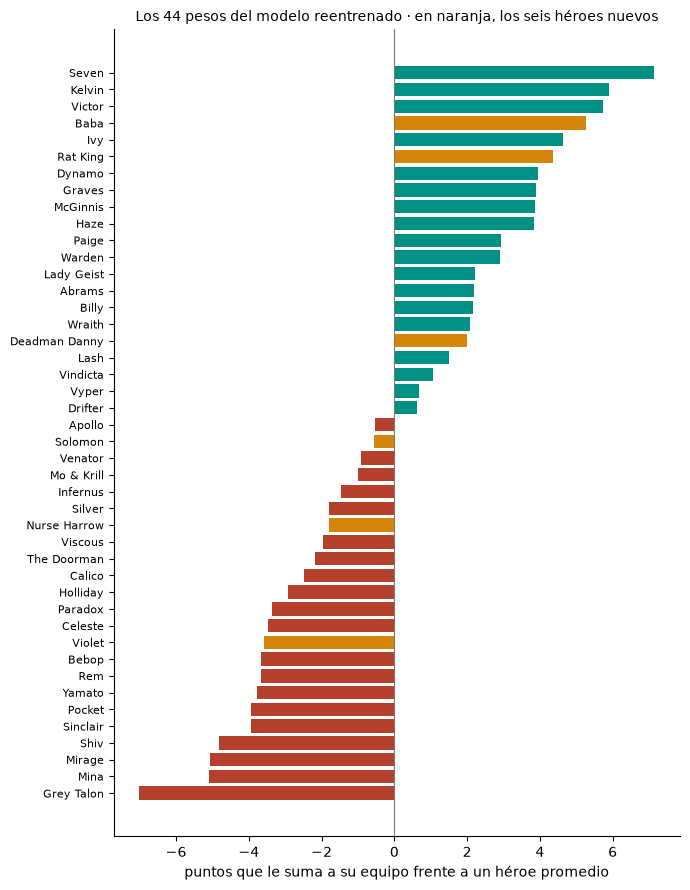

,puntos,partidas en el corte de entrenamiento
Baba,5.3,803
Rat King,4.4,2713
Deadman Danny,2.0,1709
Solomon,-0.5,846
Nurse Harrow,-1.8,1675
Violet,-3.6,1300


In [23]:
sig = lambda z: 1 / (1 + np.exp(-z))
pesos = pd.Series(modelo_final["modelo"].coef_[0], index=modelo_final["elegir"].columnas_)
pts = (sig(pesos) - 0.5) * 100
orden = pts.sort_values()
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh([NOMBRE[k] for k in orden.index], orden.values, color=[NARANJA if k in NUEVOS else (VERDE_AZUL if v > 0 else TERRACOTA) for k, v in orden.items()])
ax.axvline(0, color=GRIS, lw=0.8)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("puntos que le suma a su equipo frente a un héroe promedio")
ax.set_title("Los 44 pesos del modelo reentrenado · en naranja, los seis héroes nuevos", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame({"puntos": pts[NUEVOS].round(1), "partidas en el corte de entrenamiento": X_final[NUEVOS].ne(0).sum()}).rename(index=NOMBRE).sort_values("puntos", ascending=False)

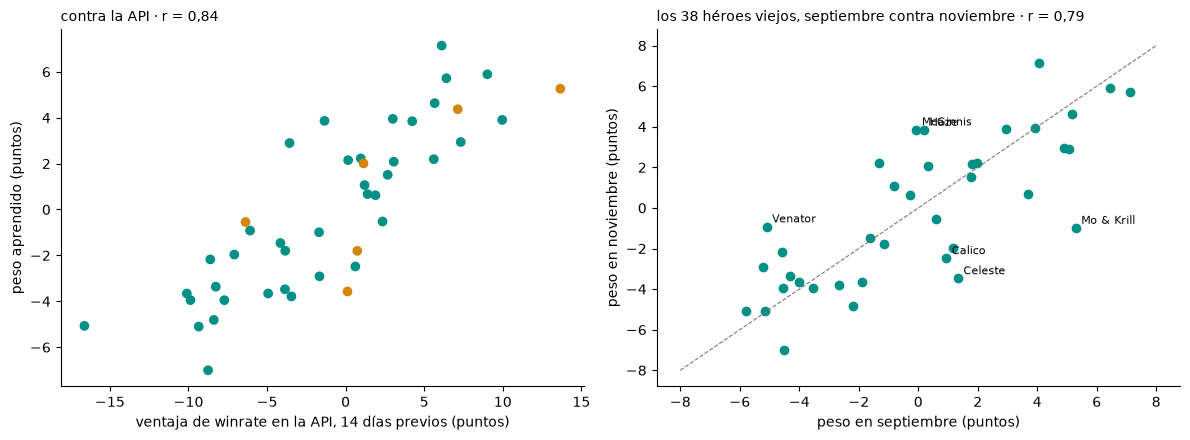

In [24]:
# Lo aprendido contra la API (winrate de los 14 días previos al corte de entrenamiento) y contra los pesos de septiembre
with open(PLATA / f"corte={ultimos[-1]}" / "dias=14" / "k=100" / "stat_tables.pkl", "rb") as f:
    adv = pickle.load(f)["hero"]
id_de = {f"hero_{s}": i for i, s in HEROES}
api = pd.Series({k: adv.get(id_de[k], 0.0) for k in pesos.index})
r_api = np.corrcoef(pesos, api)[0, 1]
viejos = [k for k in pesos.index if k not in NUEVOS]
pesos_e3 = pd.Series(paquete_e3["modelo"].named_steps["modelo"].coef_[0], index=paquete_e3["columnas"])
r_e3 = np.corrcoef(pesos[viejos], pesos_e3[viejos])[0, 1]
cambio = ((sig(pesos[viejos]) - 0.5) * 100 - (sig(pesos_e3[viejos]) - 0.5) * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(api * 100, pts, color=[NARANJA if k in NUEVOS else VERDE_AZUL for k in pesos.index])
axes[0].set_xlabel("ventaja de winrate en la API, 14 días previos (puntos)"); axes[0].set_ylabel("peso aprendido (puntos)")
axes[0].set_title(f"contra la API · r = {r_api:.2f}".replace(".", ","), fontsize=10, loc="left")
axes[1].scatter((sig(pesos_e3[viejos]) - 0.5) * 100, (sig(pesos[viejos]) - 0.5) * 100, color=VERDE_AZUL)
for k in list(cambio.index[:3]) + list(cambio.index[-3:]):
    axes[1].annotate(NOMBRE[k], ((sig(pesos_e3[k]) - 0.5) * 100, (sig(pesos[k]) - 0.5) * 100), fontsize=8, xytext=(4, 3), textcoords="offset points")
lim = [-8, 8]
axes[1].plot(lim, lim, color=GRIS, lw=0.8, ls="--")
axes[1].set_xlabel("peso en septiembre (puntos)"); axes[1].set_ylabel("peso en noviembre (puntos)")
axes[1].set_title(f"los 38 héroes viejos, septiembre contra noviembre · r = {r_e3:.2f}".replace(".", ","), fontsize=10, loc="left")
plt.tight_layout()
plt.show()

In [25]:
nuevos_pts = pts[NUEVOS].sort_values()
leer(f'''**Los héroes nuevos.** El modelo los ve más fuertes que el promedio a {', '.join(f'`{NOMBRE[k]}` ({c(v, 1)})' for k, v in nuevos_pts[::-1].items() if v > 0)}, y más débiles a {', '.join(f'`{NOMBRE[k]}` ({c(v, 1)})' for k, v in nuevos_pts.items() if v < 0)} puntos. Los 44 pesos correlacionan **{c(r_api, 2)}** con el winrate de la API, como en la sección 7§2 del notebook v3: el modelo sigue aprendiendo de las partidas lo mismo que las estadísticas, ahora también para los héroes nuevos.

**El meta se movió.** Los pesos de los 38 héroes viejos correlacionan {c(r_e3, 2)} entre septiembre y noviembre. Los que más subieron son {', '.join(f'`{NOMBRE[k]}` ({c(v, 1)})' for k, v in cambio[::-1].head(3).items())} puntos, y los que más bajaron, {', '.join(f'`{NOMBRE[k]}` ({c(v, 1)})' for k, v in cambio.head(3).items())}. Por eso el modelo de la Entrega 3 pierde también en las partidas sin héroes nuevos: hay que reentrenarlo con cada corte, no solo cuando aparece un héroe.''')

**Los héroes nuevos.** El modelo los ve más fuertes que el promedio a `Baba` (5,3), `Rat King` (4,4), `Deadman Danny` (2,0), y más débiles a `Violet` (-3,6), `Nurse Harrow` (-1,8), `Solomon` (-0,5) puntos. Los 44 pesos correlacionan **0,84** con el winrate de la API, como en la sección 7.2 del notebook v3: el modelo sigue aprendiendo de las partidas lo mismo que las estadísticas, ahora también para los héroes nuevos.

**El meta se movió.** Los pesos de los 38 héroes viejos correlacionan 0,79 entre septiembre y noviembre. Los que más subieron son `Venator` (4,2), `McGinnis` (3,9), `Haze` (3,7) puntos, y los que más bajaron, `Mo & Krill` (-6,3), `Celeste` (-4,8), `Calico` (-3,4). Por eso el modelo de la Entrega 3 pierde también en las partidas sin héroes nuevos: hay que reentrenarlo con cada corte, no solo cuando aparece un héroe.

## 8. Septiembre contra noviembre, lado a lado

Para que la comparación no dependa de números copiados, los de septiembre se recalculan acá con los cortes de la Entrega 3 (`silver/corte=T/`, 38 héroes), con los mismos modelos y la misma validación.

In [26]:
PLATA_E3 = RAIZ / "include" / "output" / "silver"
e3 = pd.concat([pd.read_parquet(p).assign(corte=p.parent.name.split("=")[1]) for p in sorted(PLATA_E3.glob("corte=*/features.parquet"))], ignore_index=True)
y3 = e3["winner"].eq("A").astype(int)
test3 = e3["corte"].eq(e3["corte"].max())
X3, y3t, g3 = e3[~test3], y3[~test3], e3.loc[~test3, "corte"]


def armar_cols(modelo, cols, escalar=True):
    return Pipeline([("elegir", ElegirColumnasFijas(cols)), ("escalar", StandardScaler() if escalar else "passthrough"), ("modelo", modelo)])


class ElegirColumnasFijas(BaseEstimator, TransformerMixin):
    def __init__(self, cols=()):
        self.cols = cols

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X[list(self.cols)]


def lado(Xt, yt, gt, comp, feats, c_win, c_todas):
    m = lambda p: medir(p, Xt=Xt, yt=yt, gt=gt)
    return {"regla": m(armar_cols(LogisticRegression(), ["hero_winrate_adv_mean"])),
            "winrates (3)": m(armar_cols(LogisticRegression(max_iter=5000, C=c_win), MEDIAS_WINRATE)),
            "composición": m(armar_cols(LogisticRegression(max_iter=5000, C=C_final), comp, escalar=False)),
            "todas": m(armar_cols(LogisticRegression(max_iter=5000, C=c_todas), feats))}


sep = lado(X3, y3t, g3, schema.COMPOSICION, schema.FEATURE_COLUMNS, 10, 0.001)
nov = lado(X_train, y_train, g_train, COMPOSICION, FEATURES,
           por_bloque.loc[legible(("winrates",)), "mejor C"], por_bloque.loc[legible(TODAS), "mejor C"])
final3 = g3.eq(g3.max())
m3 = armar_cols(LogisticRegression(max_iter=5000, C=C_final), schema.COMPOSICION, escalar=False).fit(X3[final3], y3t[final3])
p3 = m3.predict_proba(e3[test3])[:, 1]

filas = []
for b in sep:
    filas.append({"": f"{b}: AUC walk-forward", "septiembre (38 héroes)": f"{sep[b]['AUC']:.4f} ± {sep[b]['desvío AUC']:.4f}",
                  "noviembre (44 héroes)": f"{nov[b]['AUC']:.4f} ± {nov[b]['desvío AUC']:.4f}"})
filas += [
    {"": "columnas de composición / totales", "septiembre (38 héroes)": f"{len(schema.COMPOSICION)} / {len(schema.FEATURE_COLUMNS)}", "noviembre (44 héroes)": f"{len(COMPOSICION)} / {len(FEATURES)}"},
    {"": "brecha train − validación de la composición", "septiembre (38 héroes)": f"{sep['composición']['AUC en train'] - sep['composición']['AUC']:.4f}",
     "noviembre (44 héroes)": f"{nov['composición']['AUC en train'] - nov['composición']['AUC']:.4f}"},
    {"": "test de la composición: AUC / accuracy", "septiembre (38 héroes)": f"{roc_auc_score(y3[test3], p3):.4f} / {accuracy_score(y3[test3], p3 >= .5):.4f}",
     "noviembre (44 héroes)": f"{auc_t:.4f} / {acc_t:.4f}"},
    {"": "modelo de septiembre aplicado a noviembre", "septiembre (38 héroes)": "—", "noviembre (44 héroes)": f"{auc_e3_viejo:.4f} / {accuracy_score(y_t, p_e3 >= .5):.4f}"},
]
lado_a_lado = pd.DataFrame(filas).set_index("")
lado_a_lado

,septiembre (38 héroes),noviembre (44 héroes)
,,
regla: AUC walk-forward,0.6135 ± 0.0019,0.6130 ± 0.0052
winrates (3): AUC walk-forward,0.6155 ± 0.0016,0.6201 ± 0.0040
composición: AUC walk-forward,0.6139 ± 0.0025,0.6225 ± 0.0071
todas: AUC walk-forward,0.6133 ± 0.0039,0.6231 ± 0.0077
columnas de composición / totales,38 / 66,44 / 72
brecha train − validación de la composición,0.0073,0.0136
test de la composición: AUC / accuracy,0.6046 / 0.5733,0.6273 / 0.5922
modelo de septiembre aplicado a noviembre,—,0.5935 / 0.5637


In [27]:
ganador = lambda d: max(d, key=lambda b: d[b]["AUC"])
sube = {b: nov[b]["AUC"] - sep[b]["AUC"] for b in sep}
g_nov = ganador(nov)
leer(f'''**Lo que cambió.** En septiembre la mejor era `{ganador(sep)}` y la composición empataba desde atrás. En noviembre la mejor es `{g_nov}` ({c(nov[g_nov]['AUC'], 4)}){'' if g_nov == 'composición' else ', con la composición a ' + c(nov[g_nov]['AUC'] - nov['composición']['AUC'], 4) + ', dentro del empate'}: la composición pasó de {c(sep['composición']['AUC'], 4)} a **{c(nov['composición']['AUC'], 4)}**.

**La mejora no es pareja.** La regla de una columna queda igual ({c(sep['regla']['AUC'], 4)} en septiembre, {c(nov['regla']['AUC'], 4)} en noviembre). Los winrates de la API suben {c(sube['winrates (3)'], 4)}, y la composición y todas las columnas, {c(sube['composición'], 4)} y {c(sube['todas'], 4)}. Lo que mejora es lo que mira a cada héroe por separado. Una explicación posible, no verificada: un promedio de winrates resume a los doce héroes en un número, y un peso por héroe conserva lo de cada uno; con seis héroes nuevos de fuerza muy distinta (de {c(pts[NUEVOS].min(), 1)} a {c(pts[NUEVOS].max(), 1)} puntos), esa diferencia pesa más.

**En el test pasa lo mismo que en la validación:** la composición ({c(auc_t)}) y la logística con los winrates de la API ({c(auc_win_test)}) empatan, y la composición sigue siendo la única de las dos que no necesita las estadísticas.

**Lo que no cambió.** La configuración elegida es la misma (sin escalar, l2, `C = {C_final:g}`, ventana de un corte); los árboles, el bosque y el boosting siguen sin ganarle a la logística, y las estadísticas de la API siguen sin sumarle nada a la composición.

**Lo que hay que hacer con esto.** El modelo de la aplicación, entrenado en septiembre, ya está viejo: en noviembre da {c(auc_e3_viejo)} de AUC contra {c(auc_t)} del reentrenado. La regla de reentrenar con el último corte, que la Entrega 3 eligió con un mes estable, es la que sostiene al modelo cuando el juego cambia.''')

**Lo que cambió.** En septiembre la mejor era `winrates (3)` y la composición empataba desde atrás. En noviembre la mejor es `todas` (0,6231), con la composición a 0,0006, dentro del empate: la composición pasó de 0,6139 a **0,6225**.

**La mejora no es pareja.** La regla de una columna queda igual (0,6135 en septiembre, 0,6130 en noviembre). Los winrates de la API suben 0,0046, y la composición y todas las columnas, 0,0086 y 0,0099. Lo que mejora es lo que mira a cada héroe por separado. Una explicación posible, no verificada: un promedio de winrates resume a los doce héroes en un número, y un peso por héroe conserva lo de cada uno; con seis héroes nuevos de fuerza muy distinta (de -3,6 a 5,3 puntos), esa diferencia pesa más.

**En el test pasa lo mismo que en la validación:** la composición (0,627) y la logística con los winrates de la API (0,628) empatan, y la composición sigue siendo la única de las dos que no necesita las estadísticas.

**Lo que no cambió.** La configuración elegida es la misma (sin escalar, l2, `C = 0.1`, ventana de un corte); los árboles, el bosque y el boosting siguen sin ganarle a la logística, y las estadísticas de la API siguen sin sumarle nada a la composición.

**Lo que hay que hacer con esto.** El modelo de la aplicación, entrenado en septiembre, ya está viejo: en noviembre da 0,593 de AUC contra 0,627 del reentrenado. La regla de reentrenar con el último corte, que la Entrega 3 eligió con un mes estable, es la que sostiene al modelo cuando el juego cambia.

## 9. El modelo de noviembre

Se guarda en el mismo archivo que el de la Entrega 3, `notebooks/modelo_entrega3_composicion.joblib`, con su catálogo de 44 héroes: la aplicación lee siempre esa ruta, y la rama decide qué modelo hay adentro. En esta rama es el de noviembre; en `main`, el de septiembre. Por eso, en esta rama, el notebook que manda es este: volver a correr el v3 acá pisaría el modelo de noviembre con el de septiembre.

In [28]:
from sklearn.pipeline import Pipeline as _P

DESTINO = RAIZ / "notebooks" / "modelo_entrega3_composicion.joblib"
joblib.dump({"modelo": _P(modelo_final.steps[1:]), "columnas": COMPOSICION, "heroes": HEROES,
             "cortes_entrenamiento": ultimos, "corte_test": CORTE_TEST, "semilla": SEMILLA}, DESTINO)
print("guardado:", DESTINO.relative_to(RAIZ))

guardado: notebooks\modelo_entrega3_composicion.joblib
